## Importing necessary libraries

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import numpy as np

from IPython.display import display, HTML

In [2]:
execution_path = "../../../"

output_folder = "SDDSmoteBoost_Unf_All_Patient"  # Define the output folder name

RESULT_DIR = (
    f"{execution_path}/Output_Results/{output_folder}/"  # Set the result directory path
)
print("RESULT_DIR", RESULT_DIR)

EPOCH_SIZE_LIST = [
    100,
    300,
    500,
    700,
    1000,
    2000,
    3000,
]  # List of epoch sizes for training
print("EPOCH_SIZE_LIST", EPOCH_SIZE_LIST)

patient_target_grp = [  # List of patient target groups
    "SB-001",
    "SB-003",
    "SB-008",
    "SB-011",
    "SB-012",
    "SB-022",
    "SB-023",
    "SB-025",
    "SB-028",
    "SB-037",
    "SB-043",
    "SB-056",
    "SB-059",
    "SB-060",
    "SB-070",
    "SB-071",
    "SB-073",
    "SB-078",
    "SB-079",
    "SB-080",
    "SB-082",
    "SB-083",
    "SB-112",
]
print("patient_target_grp", patient_target_grp)

folds_list = [*range(1, 11)]  # List of folds for cross-validation
print("folds_list", folds_list)

data_processing_columns = [  # Columns to be used in data processing
    "Patient_ID",
    "Pop_Epoch",
    "Pop_Fold",
    "Ind_Epoch",
    "Ind_Fold",
]

RESULT_DIR ../../..//Output_Results/SDDSmoteBoost_Unf_All_Patient/
EPOCH_SIZE_LIST [100, 300, 500, 700, 1000, 2000, 3000]
patient_target_grp ['SB-001', 'SB-003', 'SB-008', 'SB-011', 'SB-012', 'SB-022', 'SB-023', 'SB-025', 'SB-028', 'SB-037', 'SB-043', 'SB-056', 'SB-059', 'SB-060', 'SB-070', 'SB-071', 'SB-073', 'SB-078', 'SB-079', 'SB-080', 'SB-082', 'SB-083', 'SB-112']
folds_list [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


### Function: `segregate_identifier`

#### Description:
Segregates the identifier from the given index based on the specified column return type.

#### Arguments:
- `index` (str): Index string to be processed.
- `column_return_type` (str): Type of identifier to segregate.

#### Returns:
str: Segregated identifier.


In [ ]:
def segregate_identifier(index, column_return_type):
    """
    Segregates the identifier from the given index based on the specified column return type.

    Args:
        index (str): Index string to be processed.
        column_return_type (str): Type of identifier to segregate.

    Returns:
        str: Segregated identifier.
    """
    if column_return_type == "Pop_Epoch":
        for i in EPOCH_SIZE_LIST:
            if str(i) + "_POP" in str(index):
                return i
    elif column_return_type == "Ind_Epoch":
        for i in EPOCH_SIZE_LIST:
            if str(i) + "_IND" in str(index):
                return i
    elif column_return_type == "Patient_ID":
        for i in patient_target_grp:
            if str(i) in str(index):
                return i
    elif column_return_type == "Pop_Fold":
        for i in folds_list:
            if "POP_FOLD_" + str(i) in str(index):
                return i
    elif column_return_type == "Ind_Fold":
        for i in folds_list:
            if "IND_FOLD_" + str(i) in str(index):
                return i

## Function: `load_csv_to_df`

### Description:
Loads a CSV file into a DataFrame and applies segregation based on index.

### Arguments:
- `RESULT_DIR` (str): Directory containing the CSV file.
- `prefix` (str): Prefix for the file.

### Returns:
pandas.DataFrame: DataFrame loaded from the CSV file with segregation applied.

In [ ]:
def load_csv_to_df(RESULT_DIR, prefix):
    """
    Loads a CSV file into a DataFrame and applies segregation based on index.

    Args:
        RESULT_DIR (str): Directory containing the CSV file.
        prefix (str): Prefix for the file.

    Returns:
        pandas.DataFrame: DataFrame loaded from the CSV file with segregation applied.
    """
    file_path = (
        RESULT_DIR
        + prefix
        + "\diagrams_n_individual_models\Ind_"
        + prefix
        + "_evaluation_metrics.csv"
    )
    df = pd.read_csv(file_path, index_col=0)

    # Apply the function to create a new column 'Segregation'
    for i in data_processing_columns:
        df[i] = df.index.map(lambda x: segregate_identifier(x, i))

    return df

In [4]:
# Defining constants
Architecture_GROUP = "TL_All_Unfrozen"  # Choose architecture group from provided options - "TL_1_Frozen", "TL_2_Frozen", "TL_3_Frozen", "TL_All_Frozen", "TL_All_Unfrozen"

# Loading the CSV file into a DataFrame
Un_frozen_All_df = load_csv_to_df(RESULT_DIR, Architecture_GROUP)

# Displaying the first 10 rows of the DataFrame
display(Un_frozen_All_df.head(10))

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard,Patient_ID,Pop_Epoch,Pop_Fold,Ind_Epoch,Ind_Fold
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-2000_IND_FOLD_1,0.492925,0.250000,0.735849,0.222222,0.764706,0.493464,0.235294,0.750000,0.492647,0.492925,0.750000,0.235294,0.264151,0.777778,0.133333,SB-083,100,1,2000,1
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-2000_IND_FOLD_2,0.497807,0.083333,0.912281,0.166667,0.825397,0.496032,0.111111,0.866667,0.488889,0.497807,0.916667,0.174603,0.087719,0.833333,0.058824,SB-083,100,1,2000,2
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-2000_IND_FOLD_3,0.506614,0.142857,0.870370,0.222222,0.796610,0.509416,0.173913,0.831858,0.502886,0.506614,0.857143,0.203390,0.129630,0.777778,0.095238,SB-083,100,1,2000,3
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-3000_IND_FOLD_1,0.430425,0.125000,0.735849,0.125000,0.735849,0.430425,0.125000,0.735849,0.430425,0.430425,0.875000,0.264151,0.264151,0.875000,0.066667,SB-083,100,1,3000,1
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-3000_IND_FOLD_2,0.528509,0.250000,0.807018,0.214286,0.836364,0.525325,0.230769,0.821429,0.526099,0.528509,0.750000,0.163636,0.192982,0.785714,0.130435,SB-083,100,1,3000,2
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-3000_IND_FOLD_3,0.478836,0.142857,0.814815,0.166667,0.785714,0.476190,0.153846,0.800000,0.476923,0.478836,0.857143,0.214286,0.185185,0.833333,0.083333,SB-083,100,1,3000,3
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-100_IND_FOLD_1,0.666667,0.666667,0.666667,0.230769,0.930233,0.580501,0.342857,0.776699,0.559778,0.666667,0.333333,0.069767,0.333333,0.769231,0.206897,SB-083,100,1,100,1
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-300_IND_FOLD_1,0.533333,0.333333,0.733333,0.157895,0.880000,0.518947,0.214286,0.800000,0.507143,0.533333,0.666667,0.120000,0.266667,0.842105,0.120000,SB-083,100,1,300,1
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-500_IND_FOLD_1,0.563889,0.444444,0.683333,0.173913,0.891304,0.532609,0.250000,0.773585,0.511792,0.563889,0.555556,0.108696,0.316667,0.826087,0.142857,SB-083,100,1,500,1
source-_size__5182_TL_All_Unfrozen_100_POP_FOLD_1_SB-083-700_IND_FOLD_1,0.469444,0.222222,0.716667,0.105263,0.860000,0.482632,0.142857,0.781818,0.462338,0.469444,0.777778,0.140000,0.283333,0.894737,0.076923,SB-083,100,1,700,1


## Function: `grouping_df`

### Description:
Groups the DataFrame by specified columns and calculates the mean.

### Arguments:
- `df` (pandas.DataFrame): DataFrame to be grouped.

### Returns:
dict: Dictionary containing grouped DataFrames.

In [5]:
def grouping_df(df):
    """
    Groups the DataFrame by specified columns and calculates the mean.

    Args:
        df (pandas.DataFrame): DataFrame to be grouped.

    Returns:
        dict: Dictionary containing grouped DataFrames.
    """
    grouped_dfs = {}

    # Group the DataFrame by each column in data_processing_columns
    for column in data_processing_columns:
        # Calculate mean for numeric columns within each group and drop irrelevant columns
        grouped_df = (
            df.groupby([column])
            .mean(numeric_only=True)
            .drop(columns=data_processing_columns, errors="ignore")
        )
        grouped_dfs[column] = grouped_df

    return grouped_dfs


# Group the DataFrame Un_frozen_All_df
grouped_dfs = grouping_df(Un_frozen_All_df)

# Access the grouped DataFrames using column_type
# grp_df_patient_id = grouped_dfs["Patient_ID"]
grp_df_pop_epoch = grouped_dfs["Pop_Epoch"]
grp_df_ind_epoch = grouped_dfs["Ind_Epoch"]
# grp_df_pop_fold = grouped_dfs["Pop_Fold"]
# grp_df_ind_fold = grouped_dfs["Ind_Fold"]

# Display the grouped DataFrames
# display(grp_df_patient_id)
display(grp_df_pop_epoch)
display(grp_df_ind_epoch)
# display(grp_df_pop_fold)
# display(grp_df_ind_fold)

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Pop_Epoch,,,,,,,,,,,,,,,
100,0.599639,0.376059,0.823218,0.358019,0.839245,0.598632,0.352989,0.828724,0.590857,0.599639,0.623941,0.160755,0.176782,0.641981,0.228668
300,0.601781,0.379109,0.824453,0.359515,0.840574,0.600044,0.355738,0.830165,0.592951,0.601781,0.620891,0.159426,0.175547,0.640485,0.230947
500,0.605288,0.384109,0.826467,0.364661,0.841962,0.603311,0.361410,0.831910,0.596660,0.605288,0.615891,0.158038,0.173533,0.635339,0.235221
700,0.609286,0.394470,0.824103,0.370555,0.843087,0.606821,0.368791,0.831239,0.600015,0.609286,0.605530,0.156913,0.175897,0.629445,0.240837
1000,0.610677,0.396557,0.824798,0.372783,0.843564,0.608174,0.371141,0.831832,0.601487,0.610677,0.603443,0.156436,0.175202,0.627217,0.242520
2000,0.613385,0.398384,0.828386,0.370207,0.845290,0.607748,0.365207,0.833616,0.599411,0.613385,0.601616,0.154710,0.171614,0.629793,0.238642
3000,0.611214,0.396033,0.826395,0.365717,0.844278,0.604997,0.363022,0.832209,0.597615,0.611214,0.603967,0.155722,0.173605,0.634283,0.237721


,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Ind_Epoch,,,,,,,,,,,,,,,
100,0.628538,0.468102,0.788974,0.369744,0.854861,0.612303,0.399492,0.817774,0.608633,0.628538,0.531898,0.145139,0.211026,0.630256,0.264561
300,0.609035,0.391195,0.826876,0.368845,0.843102,0.605974,0.364772,0.832478,0.598625,0.609035,0.608805,0.156898,0.173124,0.631155,0.237694
500,0.602516,0.376607,0.828426,0.361842,0.840233,0.601038,0.354760,0.831936,0.593348,0.602516,0.623393,0.159767,0.171574,0.638158,0.230046
700,0.599103,0.366915,0.831292,0.359885,0.838642,0.599263,0.349100,0.832682,0.590891,0.599103,0.633085,0.161358,0.168708,0.640115,0.226047
1000,0.597856,0.365453,0.830259,0.357457,0.838299,0.597878,0.347121,0.831894,0.589508,0.597856,0.634547,0.161701,0.169741,0.642543,0.224426
2000,0.606076,0.376476,0.835677,0.370171,0.841088,0.605630,0.360120,0.836158,0.598139,0.606076,0.623524,0.158912,0.164323,0.629829,0.235256
3000,0.608144,0.379973,0.836316,0.373511,0.841775,0.607643,0.362932,0.836773,0.599852,0.608144,0.620027,0.158225,0.163684,0.626489,0.236527


## Result DataFrame

### Description:
DataFrame containing the index of the maximum value in each grouped DataFrame.

### Contents:
The DataFrame consists of the index of the maximum value in each grouped DataFrame.

### Example:
```python
# Display the result DataFrame
display(idxmax_result)

In [6]:
# Initialize an empty DataFrame to store the results
idxmax_result = pd.DataFrame()

# Iterate over each grouped DataFrame
for df_name, df in grouped_dfs.items():
    # Sort the DataFrame by the values of the current column
    sorted_df = df.sort_values(by=df_name)

    # Find the index of the maximum value in each column and store it in a temporary DataFrame
    temp_result = pd.DataFrame(sorted_df.idxmax(), columns=[df_name])

    # Concatenate the temporary DataFrame with the result DataFrame along the columns axis
    idxmax_result = pd.concat([idxmax_result, temp_result], axis=1)

# Display the result DataFrame
display(idxmax_result)

,Patient_ID,Pop_Epoch,Pop_Fold,Ind_Epoch,Ind_Fold
Weighted Accuracy,SB-011,2000,2,100,3
Sensitivity/Recall,SB-011,2000,2,100,3
Specificity,SB-011,2000,1,3000,3
Precision_class0,SB-078,1000,1,3000,3
Precision_class1,SB-011,2000,2,100,1
Precision_avg,SB-011,1000,2,100,3
F1_class0,SB-078,1000,2,100,3
F1_class1,SB-011,2000,1,3000,1
F1_avg,SB-011,1000,1,100,3
auc_roc_score,SB-011,2000,2,100,3


## Function: `visualize_arch_epochs`

### Description:
Visualizes the epochs for each architecture group.

### Arguments:
- `df` (dict): Dictionary containing grouped DataFrames.
- `epoch_type` (str): Type of epoch to visualize.
- `filepath` (str): Path to save the visualization.
- `Architecture_GROUP` (str): Name of the architecture group.

### Returns:
None

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Pop_Epoch,,,,,,,,,,,,,,,
100,0.599639,0.376059,0.823218,0.358019,0.839245,0.598632,0.352989,0.828724,0.590857,0.599639,0.623941,0.160755,0.176782,0.641981,0.228668
300,0.601781,0.379109,0.824453,0.359515,0.840574,0.600044,0.355738,0.830165,0.592951,0.601781,0.620891,0.159426,0.175547,0.640485,0.230947
500,0.605288,0.384109,0.826467,0.364661,0.841962,0.603311,0.361410,0.831910,0.596660,0.605288,0.615891,0.158038,0.173533,0.635339,0.235221
700,0.609286,0.394470,0.824103,0.370555,0.843087,0.606821,0.368791,0.831239,0.600015,0.609286,0.605530,0.156913,0.175897,0.629445,0.240837
1000,0.610677,0.396557,0.824798,0.372783,0.843564,0.608174,0.371141,0.831832,0.601487,0.610677,0.603443,0.156436,0.175202,0.627217,0.242520
2000,0.613385,0.398384,0.828386,0.370207,0.845290,0.607748,0.365207,0.833616,0.599411,0.613385,0.601616,0.154710,0.171614,0.629793,0.238642
3000,0.611214,0.396033,0.826395,0.365717,0.844278,0.604997,0.363022,0.832209,0.597615,0.611214,0.603967,0.155722,0.173605,0.634283,0.237721


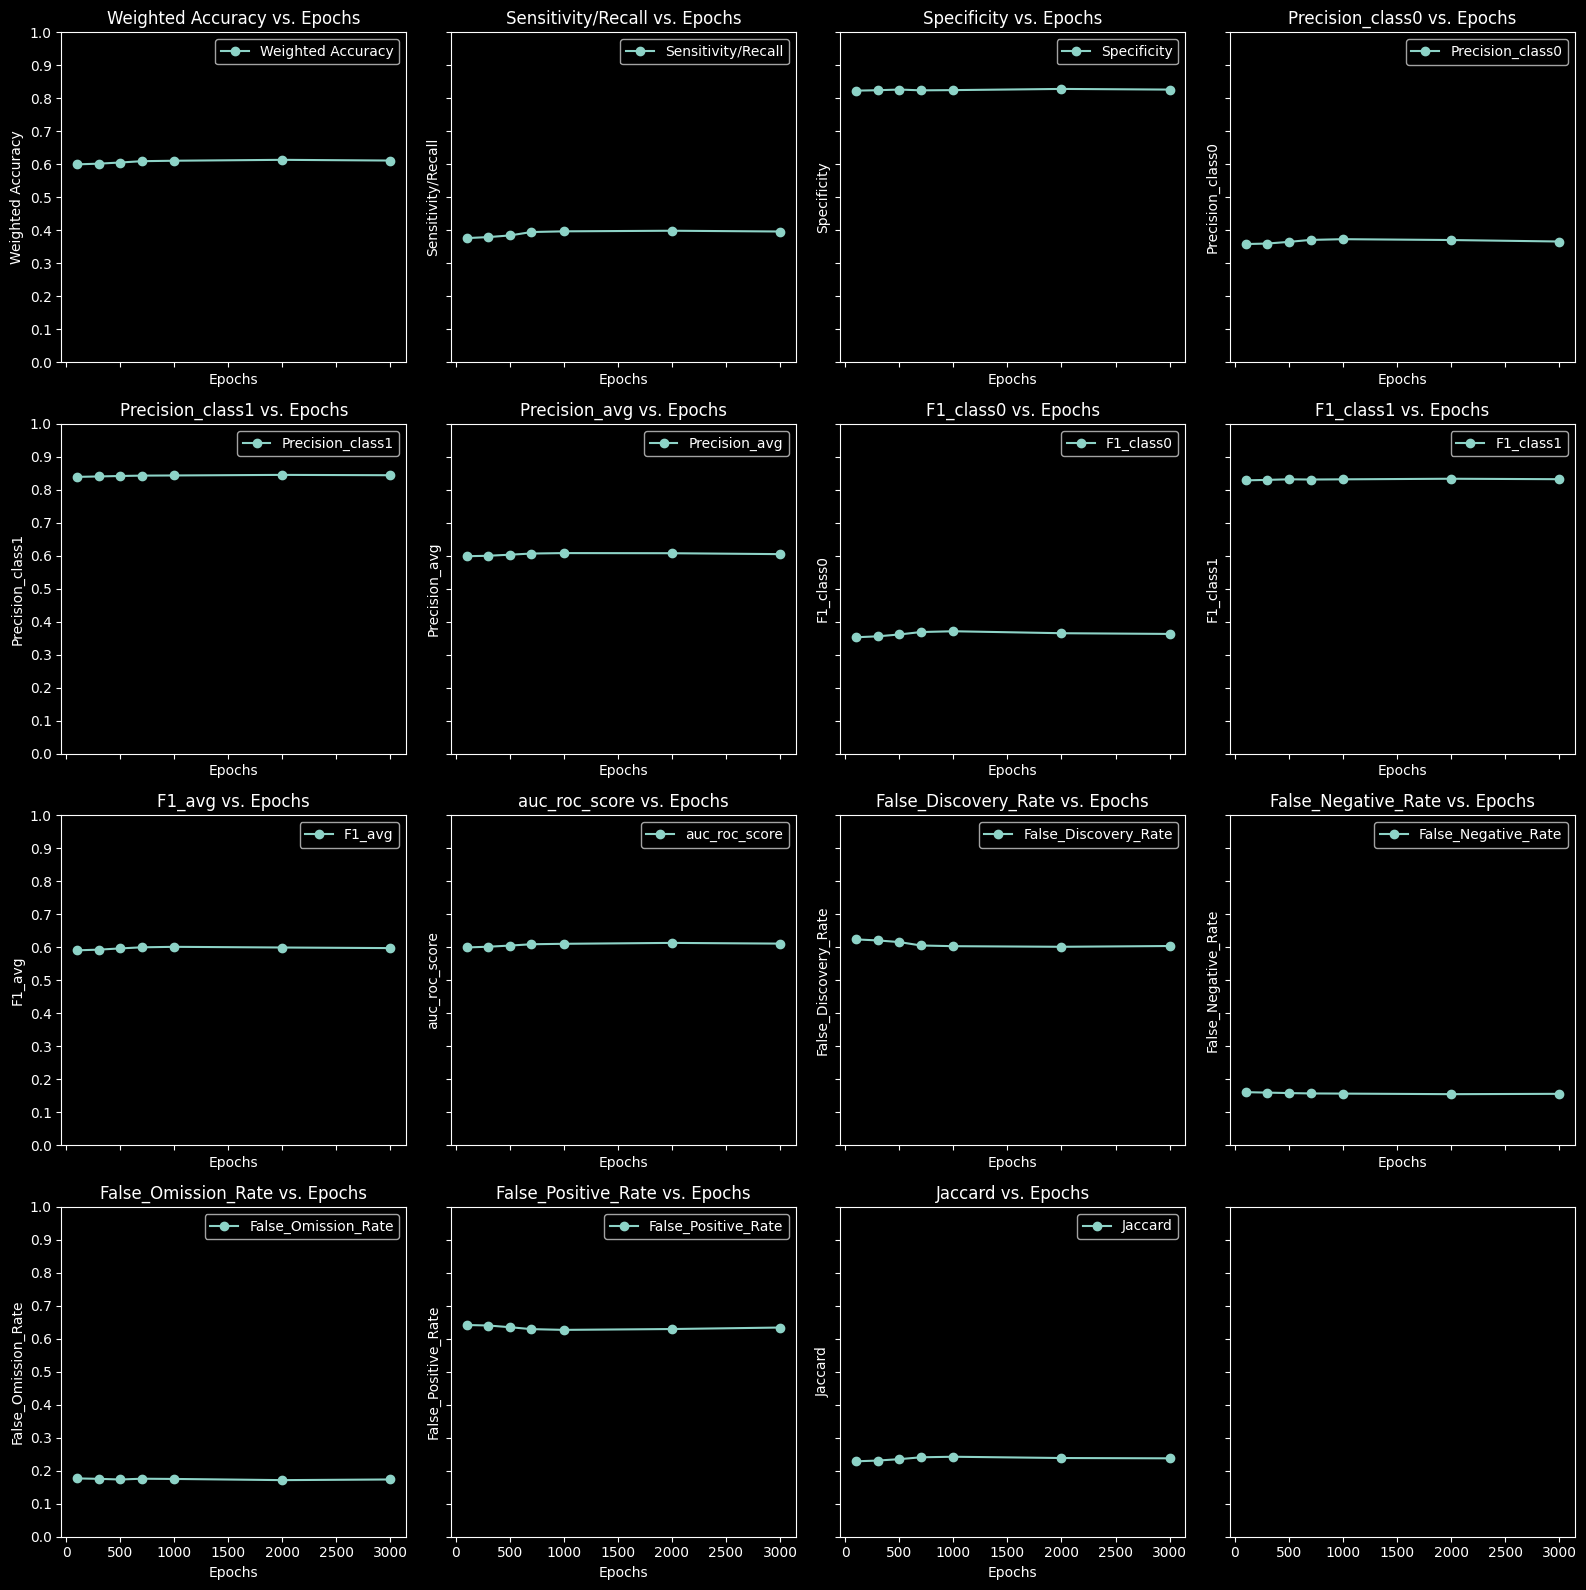

,Weighted Accuracy,Sensitivity/Recall,Specificity,Precision_class0,Precision_class1,Precision_avg,F1_class0,F1_class1,F1_avg,auc_roc_score,False_Discovery_Rate,False_Negative_Rate,False_Omission_Rate,False_Positive_Rate,Jaccard
Ind_Epoch,,,,,,,,,,,,,,,
100,0.628538,0.468102,0.788974,0.369744,0.854861,0.612303,0.399492,0.817774,0.608633,0.628538,0.531898,0.145139,0.211026,0.630256,0.264561
300,0.609035,0.391195,0.826876,0.368845,0.843102,0.605974,0.364772,0.832478,0.598625,0.609035,0.608805,0.156898,0.173124,0.631155,0.237694
500,0.602516,0.376607,0.828426,0.361842,0.840233,0.601038,0.354760,0.831936,0.593348,0.602516,0.623393,0.159767,0.171574,0.638158,0.230046
700,0.599103,0.366915,0.831292,0.359885,0.838642,0.599263,0.349100,0.832682,0.590891,0.599103,0.633085,0.161358,0.168708,0.640115,0.226047
1000,0.597856,0.365453,0.830259,0.357457,0.838299,0.597878,0.347121,0.831894,0.589508,0.597856,0.634547,0.161701,0.169741,0.642543,0.224426
2000,0.606076,0.376476,0.835677,0.370171,0.841088,0.605630,0.360120,0.836158,0.598139,0.606076,0.623524,0.158912,0.164323,0.629829,0.235256
3000,0.608144,0.379973,0.836316,0.373511,0.841775,0.607643,0.362932,0.836773,0.599852,0.608144,0.620027,0.158225,0.163684,0.626489,0.236527


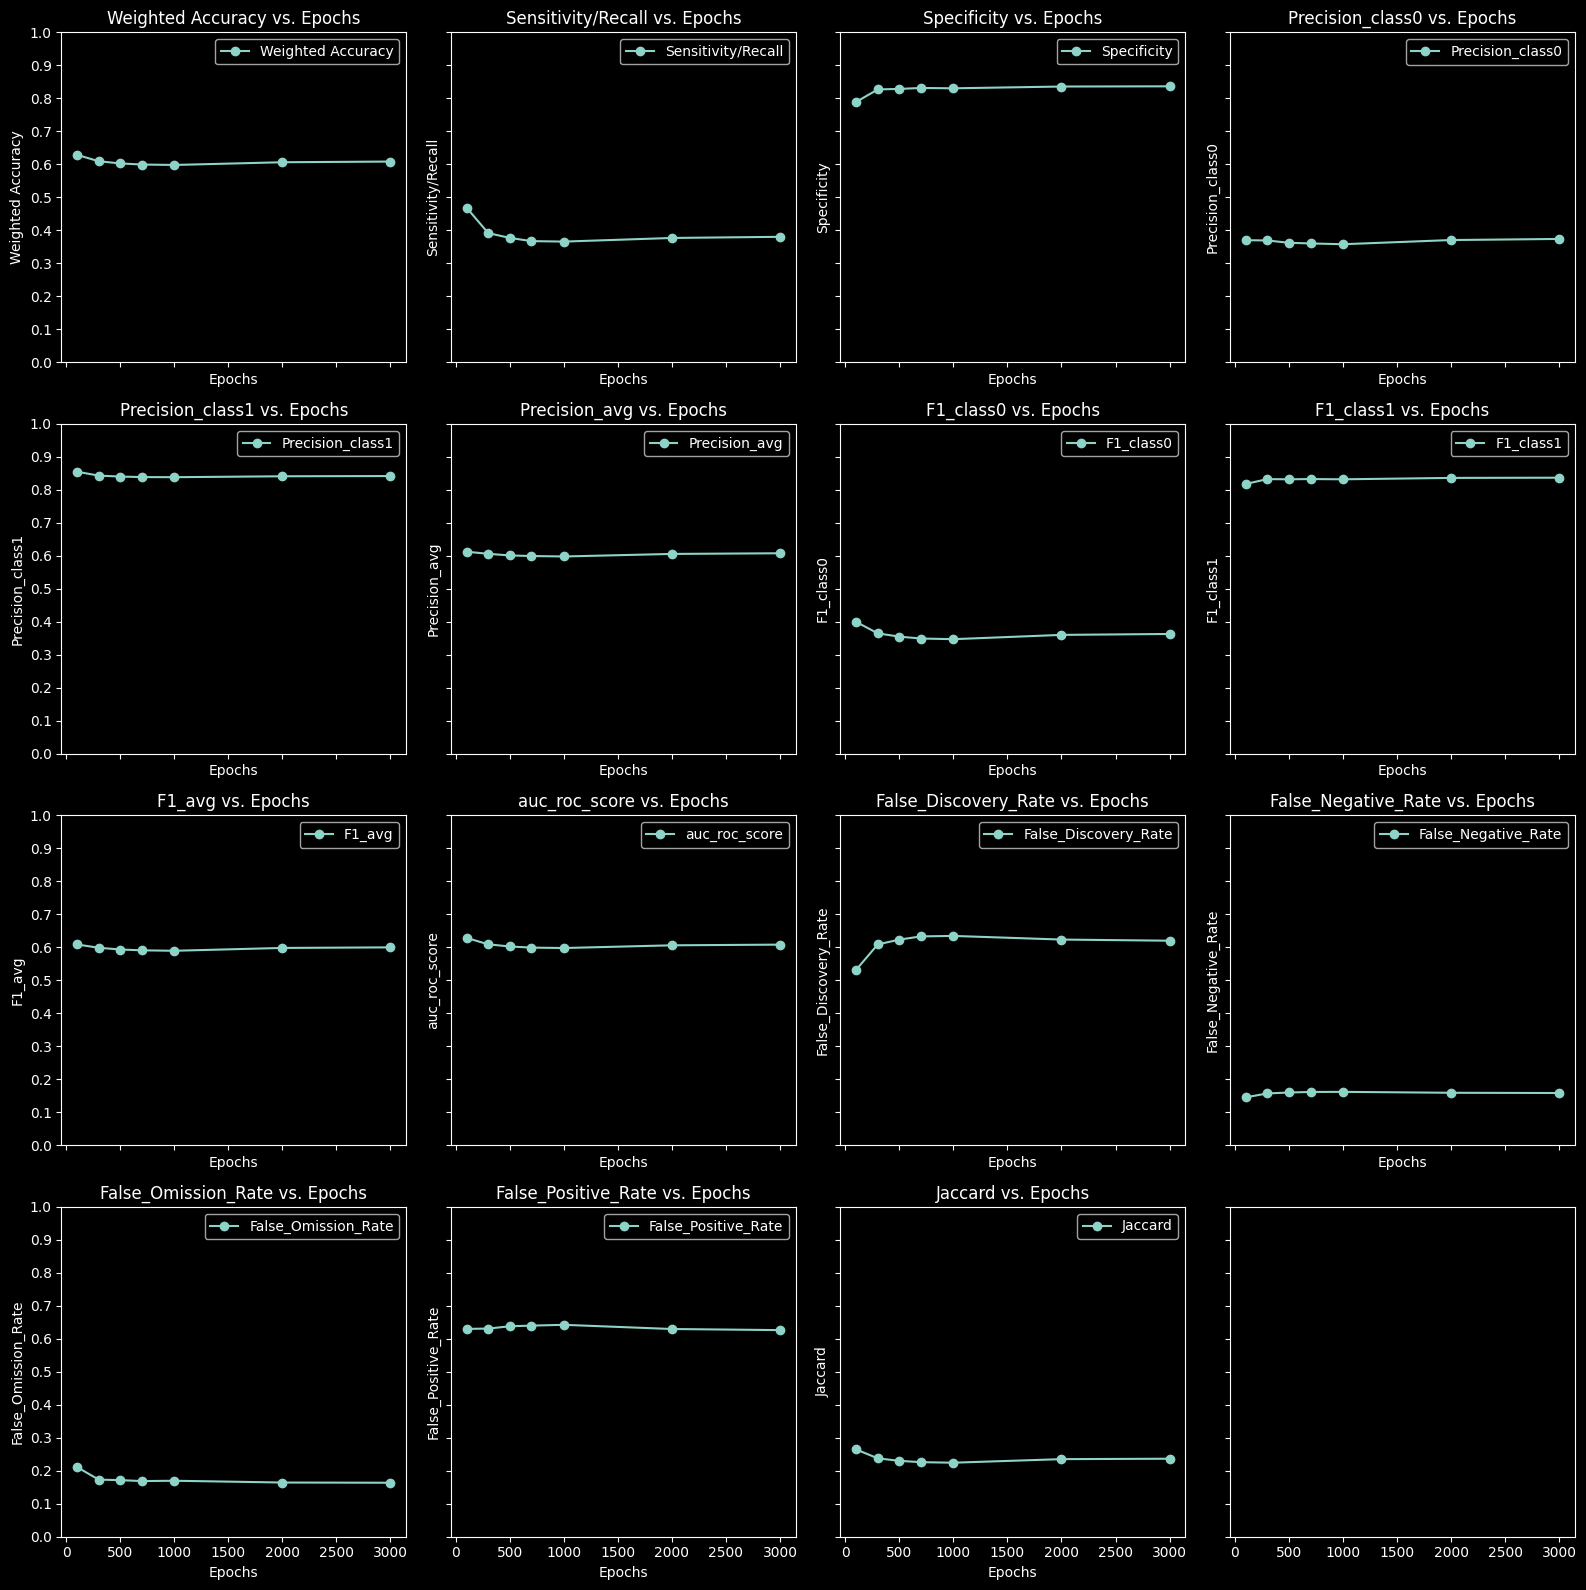

In [7]:
def visualize_arch_epochs(df, epoch_type, filepath, Architecture_GROUP):
    """
    Visualizes the epochs for each architecture group.

    Args:
        df (dict): Dictionary containing grouped DataFrames.
        epoch_type (str): Type of epoch to visualize.
        filepath (str): Path to save the visualization.
        Architecture_GROUP (str): Name of the architecture group.

    Returns:
        None
    """
    # Sample DataFrame (replace this with your actual DataFrame)
    data = df[epoch_type]

    df = pd.DataFrame(data)
    display(df)

    # Determine the number of rows and columns in the subplot grid
    num_cols = 4
    num_rows = -(
        -len(df.columns) // num_cols
    )  # Ceiling division to get the number of rows

    # Create subplots
    fig, axes = plt.subplots(
        nrows=num_rows, ncols=num_cols, figsize=(16, 16), sharey=True, sharex=True
    )

    # Plot each column against the 'epochs' column
    for idx, column in enumerate(data.columns):  # Exclude 'epochs' column
        row = idx // num_cols
        col = idx % num_cols
        axes[row, col].plot(EPOCH_SIZE_LIST, df[column], marker="o", label=column)
        axes[row, col].set_xlabel("Epochs")
        y_ticks = np.arange(0.0, 1.1, 0.1)
        axes[row, col].set_yticks(y_ticks)
        axes[row, col].set_yticklabels(["{:.1f}".format(val) for val in y_ticks])
        axes[row, col].set_ylabel(column)
        axes[row, col].set_title(f"{column} vs. Epochs")
        axes[row, col].legend()

    # Adjust layout
    plt.tight_layout()
    plt.savefig(
        f"{filepath}/{Architecture_GROUP}/{Architecture_GROUP}_{epoch_type}.png"
    )
    plt.show()


# Visualize epochs for Population Epoch and Individual Epoch
visualize_arch_epochs(grouped_dfs, "Pop_Epoch", RESULT_DIR, Architecture_GROUP)
visualize_arch_epochs(grouped_dfs, "Ind_Epoch", RESULT_DIR, Architecture_GROUP)

## Function: `combining_top_percent_df`

### Description:
This function combines the top percentage of rows from a DataFrame based on specified columns. It is useful for selecting a subset of data that represents the highest values across different columns.

### Arguments:
- `df` (DataFrame): The input DataFrame.
- `columns_list` (dict): A dictionary specifying different types of columns to consider.
- `top_percent` (int, optional): The percentage of top rows to be combined. Defaults to 10.

### Returns:
DataFrame: A DataFrame containing the combined top percentage of rows based on specified columns.

### Notes:
- This function sorts the DataFrame by each specified column in `columns_list` and selects the top percentage of rows.
- It then combines these selected rows into a single DataFrame.
- Different sets of columns can be provided in `columns_list` to prioritize different metrics or features.

### Examples:
```python
combined_top_df = combining_top_percent_df(df, columns_list, top_percent=10)

In [8]:
def combining_top_percent_df(df, columns_list, top_percent=10):
    top_percent_value = int(top_percent / 100 * len(df))
    combined_top_percent_dfs = pd.DataFrame()

    for column in columns_list:
        temp_df = df.sort_values(by=column, ascending=False).head(top_percent_value)[
            columns_list
            + ["Patient_ID", "Pop_Epoch", "Pop_Fold", "Ind_Epoch", "Ind_Fold"]
        ]

        combined_top_percent_dfs = pd.concat(
            [combined_top_percent_dfs, temp_df], axis=0
        )
    return combined_top_percent_dfs


# Dictionary containing lists of columns categorized by types
columns_list = {
    "All Columns": [
        "Weighted Accuracy",
        "Sensitivity/Recall",
        "Specificity",
        "Precision_class0",
        "Precision_class1",
        "Precision_avg",
        "F1_class0",
        "F1_class1",
        "F1_avg",
        "auc_roc_score",
        "False_Discovery_Rate",
        "False_Negative_Rate",
        "False_Omission_Rate",
        "False_Positive_Rate",
        "Jaccard",
    ],
    "Priority Columns": [
        "Weighted Accuracy",
        "Sensitivity/Recall",
        "Specificity",
        "Precision_avg",
    ],
}

# Array containing percentage values
percent_list = np.arange(10, 60, 10)

# Print column lists for each type
for column_type, column_values in columns_list.items():
    print(f"List of {column_type}: {column_values}", "\n")

# List of epoch types
epoch_type_list = ["Pop_Epoch", "Ind_Epoch"]

# Initialize DataFrames for population and individual epochs
pop_epoch_df = pd.DataFrame()
ind_epoch_df = pd.DataFrame()

# Iterate over epoch types
for epoch_type in epoch_type_list:
    epoch_percent_list = []
    epoch_all_column_list = []
    epoch_priority_column_list = []

    # Iterate over percentage values
    for percent_value in percent_list:
        epoch_percent_list.append(percent_value)

        # Iterate over column types
        for column_type, column_values in columns_list.items():
            # Combine top percent of data based on column values
            combined_top_percent_df = combining_top_percent_df(
                Un_frozen_All_df, column_values, percent_value
            )

            # Create DataFrame for top percent value counts
            temp_df = pd.DataFrame(
                combined_top_percent_df.value_counts(epoch_type),
                columns=[f"{epoch_type}_top_{percent_value}%_{column_type}"],
            )
            display(temp_df)

            # Append max value counts based on column type
            if column_type == "Priority Columns":
                epoch_priority_column_list.append(
                    combined_top_percent_df.value_counts(epoch_type).idxmax()
                )
            elif column_type == "All Columns":
                epoch_all_column_list.append(
                    combined_top_percent_df.value_counts(epoch_type).idxmax()
                )

    # Update DataFrames based on epoch type
    if epoch_type == "Pop_Epoch":
        pop_epoch_df = pd.DataFrame(
            data={
                "epoch_percent_list": epoch_percent_list,
                "epoch_priority_column_list": epoch_priority_column_list,
                "epoch_all_column_list": epoch_all_column_list,
            },
            columns=[
                "epoch_percent_list",
                "epoch_priority_column_list",
                "epoch_all_column_list",
            ],
        )
        pop_epoch_df.set_index("epoch_percent_list", inplace=True)
    elif epoch_type == "Ind_Epoch":
        ind_epoch_df = pd.DataFrame(
            data={
                "epoch_percent_list": epoch_percent_list,
                "epoch_priority_column_list": epoch_priority_column_list,
                "epoch_all_column_list": epoch_all_column_list,
            },
            columns=[
                "epoch_percent_list",
                "epoch_priority_column_list",
                "epoch_all_column_list",
            ],
        )
        ind_epoch_df.set_index("epoch_percent_list", inplace=True)

List of All Columns: ['Weighted Accuracy', 'Sensitivity/Recall', 'Specificity', 'Precision_class0', 'Precision_class1', 'Precision_avg', 'F1_class0', 'F1_class1', 'F1_avg', 'auc_roc_score', 'False_Discovery_Rate', 'False_Negative_Rate', 'False_Omission_Rate', 'False_Positive_Rate', 'Jaccard'] 

List of Priority Columns: ['Weighted Accuracy', 'Sensitivity/Recall', 'Specificity', 'Precision_avg'] 



,Pop_Epoch_top_10%_All Columns
Pop_Epoch,
3000,3961
2000,3848
700,3638
1000,3631
300,3484
100,3423
500,3365


,Pop_Epoch_top_10%_Priority Columns
Pop_Epoch,
2000,1096
3000,1093
1000,979
700,968
300,903
500,863
100,858


,Pop_Epoch_top_20%_All Columns
Pop_Epoch,
3000,7801
2000,7573
700,7379
1000,7270
500,7009
300,6867
100,6816


,Pop_Epoch_top_20%_Priority Columns
Pop_Epoch,
2000,2183
3000,2168
700,1959
1000,1926
500,1830
300,1748
100,1710


...

,Ind_Epoch_top_30%_Priority Columns
Ind_Epoch,
100,3162
3000,3080
2000,3073
300,2841
700,2751
1000,2692
500,2685


,Ind_Epoch_top_40%_All Columns
Ind_Epoch,
100,15264
2000,14919
3000,14822
300,14516
500,14036
700,13981
1000,13892


,Ind_Epoch_top_40%_Priority Columns
Ind_Epoch,
100,4115
2000,4074
3000,4044
300,3852
500,3672
700,3672
1000,3619


,Ind_Epoch_top_50%_All Columns
Ind_Epoch,
100,18854
3000,18303
2000,18264
300,18162
500,17892
700,17685
1000,17620


,Ind_Epoch_top_50%_Priority Columns
Ind_Epoch,
2000,5018
100,5012
3000,5003
300,4819
500,4722
700,4636
1000,4598


In [9]:
display("Pop Epoch List", pop_epoch_df)
display("Ind Epoch List", ind_epoch_df)

'Pop Epoch List'

,epoch_priority_column_list,epoch_all_column_list
epoch_percent_list,,
10,2000,3000
20,2000,3000
30,2000,2000
40,2000,2000
50,2000,2000


'Ind Epoch List'

,epoch_priority_column_list,epoch_all_column_list
epoch_percent_list,,
10,100,100
20,100,100
30,100,100
40,100,100
50,2000,100


## Before adding epochs 2000 and 3000, 1000_100 combination had most number of high column_values in top 10% of each columns i.e Weighted Accuracy, Sensitivity/Recall, Specificity
## However, after adding 2000 and 3000 epochs, we should consider 2000_100 as best epoch combination, as its at top in most cases
## Point of note - 3000 for pop epoch is best when considering all columns and top 10% for those columns